# 03. Exploring demand

**Where we are:** notebook 02 built clean half-hourly tables and measured NESO's forecast
(MAE about 689 MW from June 2024). Its errors are largest at midday and growing.

**What this notebook does:** looks at the patterns a forecast has to capture: the long-term
trend, the yearly, weekly and daily cycles, holidays, Christmas, the 2020 lockdown, and the
effect of embedded solar and wind. Each finding ends in a decision for the model.

**Why only data before June 2024:** the final test window starts on 2024-06-01. If I explored
the test period too, what I saw there could shape the model, and the test score would look
better than it should. So everything here stops at 2024-05-31.

**Background reading**
- [Forecasting: Principles and Practice, section 2.3, time series patterns](https://otexts.com/fpp3/tspatterns.html)
- [Duck curve](https://en.wikipedia.org/wiki/Duck_curve): how solar reshapes daily demand


## Step 1. Set up and load

**What:** load `demand.parquet` from notebook 02 and add local-time columns.

**Why local time:** people switch the kettle on by the clock on the wall, not by UTC. Daily
patterns line up in local time, so calendar features use it. The UTC timestamp stays as the key.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROCESSED = Path("../data/processed")
TEST_START = pd.Timestamp("2024-06-01", tz="Europe/London")

BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "figure.dpi": 90,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e4e4e0",
    "lines.linewidth": 2,
})

demand = pd.read_parquet(PROCESSED / "demand.parquet")
demand = demand[demand["start_utc"] < TEST_START].copy()

local = demand["start_utc"].dt.tz_convert("Europe/London")
demand["date"] = pd.to_datetime(demand["Date"])
demand["year"] = demand["date"].dt.year
demand["month"] = demand["date"].dt.month
demand["weekday"] = demand["date"].dt.dayofweek
demand["local_hour"] = local.dt.hour + local.dt.minute / 60
demand["underlying"] = demand["ND"] + demand["EMBEDDED_SOLAR_GENERATION"] + demand["EMBEDDED_WIND_GENERATION"]

daily = demand.groupby("date").agg(ND=("ND", "mean"), underlying=("underlying", "mean")).asfreq("D")
print(demand.shape, demand["Date"].min(), "to", demand["Date"].max())


(112462, 30) 2018-01-01 to 2024-05-31


## Step 2. Long-term trend

**What:** a rolling 365-day mean of `ND`, and of "underlying" demand, which adds the estimated
embedded solar and wind back in.

**Why a rolling year:** a calendar-year mean is distorted by part years (2024 here only runs to
May, mostly winter). A 365-day window always holds one of each season.

**Why underlying demand:** `ND` only counts what the transmission network carries. Embedded
generation is used locally and never shows up in it. Adding it back separates "people use less
electricity" from "more of it is generated locally".


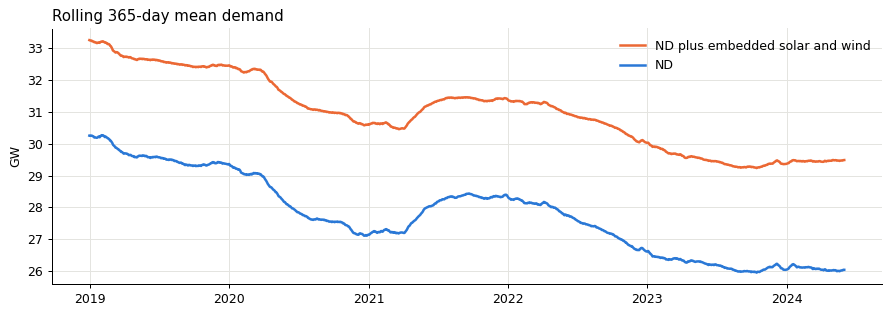

                 ND  underlying
date                           
2018-12-31  30247.0     33235.0
2024-05-31  26051.0     29484.0


In [2]:
rolling = daily.rolling(365, min_periods=365).mean().dropna()

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(rolling.index, rolling["underlying"] / 1000, color=ORANGE, label="ND plus embedded solar and wind")
ax.plot(rolling.index, rolling["ND"] / 1000, color=BLUE, label="ND")
ax.set_ylabel("GW")
ax.set_title("Rolling 365-day mean demand", loc="left")
ax.legend(loc="upper right", frameon=False)
fig.tight_layout()
plt.show()

print(rolling.iloc[[0, -1]].round(0).to_string())


**Found:**

- The rolling yearly mean of `ND` fell from 30.2 GW (year to end 2018) to 26.1 GW (year to May
  2024). Underlying demand fell from 33.2 GW to 29.5 GW.
- So embedded generation explains only a small part of the fall (about 0.4 of the 4.1 GW, going by
  NESO's estimates). Most of it is lower consumption.
- The fall is not smooth: a dip in 2020 (the lockdown), a recovery in 2021, a steady fall
  through 2022 into 2023, which lines up in time with the jump in energy prices, and a flat
  stretch since mid-2023.

**Decision:** the demand level shifts over the years, so a model fitted on 2018 must not assume
2018 levels. Recent demand lags (Step 11) carry the current level into the forecast. Day 6 will
also compare training on all years against training on recent years only.


## Step 3. Yearly cycle

**What:** the typical daily mean demand for each week of the year, across all years.

**Why:** heating and lighting drive demand up in winter. This cycle is the largest pattern in
the data. Most of it is temperature and daylight, which the weather features on Day 4 should
explain better than a calendar can.


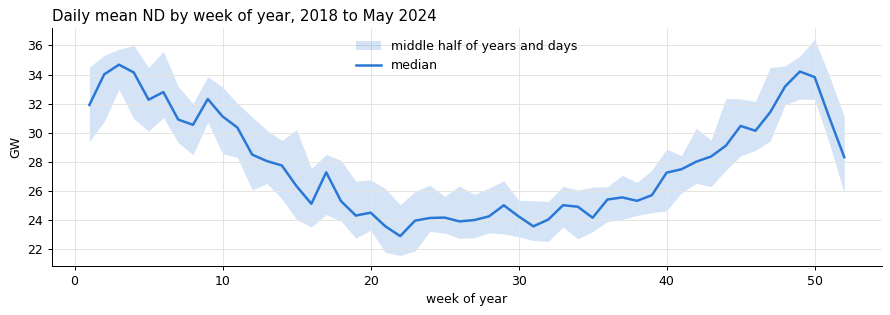

winter (weeks 1-6) to summer (weeks 27-32) ratio: 1.38


In [3]:
week = daily.index.isocalendar().week.clip(upper=52)
by_week = daily["ND"].groupby(week.values).describe()

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.fill_between(by_week.index, by_week["25%"] / 1000, by_week["75%"] / 1000, color=BLUE, alpha=0.2,
                linewidth=0, label="middle half of years and days")
ax.plot(by_week.index, by_week["50%"] / 1000, color=BLUE, label="median")
ax.set_xlabel("week of year")
ax.set_ylabel("GW")
ax.set_title("Daily mean ND by week of year, 2018 to May 2024", loc="left")
ax.legend(loc="upper center", frameon=False)
fig.tight_layout()
plt.show()

print("winter (weeks 1-6) to summer (weeks 27-32) ratio:",
      round(by_week.loc[1:6, "50%"].mean() / by_week.loc[27:32, "50%"].mean(), 2))


**Found:** winter demand (weeks 1 to 6) is about 38% higher than midsummer (weeks 27 to 32).
The lowest weeks are late May and early June, around 23 GW, when days are long and heating is
off. The ups and downs between spring weeks come partly from Easter moving between weeks and
partly from small samples (six or seven years per week). The drop in week 52 is Christmas.

**Decision:** temperature and daylight features (Day 4) should carry most of this. Day of year
can stay in as a calendar feature for what weather does not explain.


## Step 4. Weekly cycle

**What:** mean demand on each day of the week, relative to the average weekday.

**Why:** offices, shops and factories run on a weekly schedule, so weekends look different.
This tells us whether "weekday or weekend" is enough, or whether each day needs its own label.


In [4]:
day_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
by_day = daily["ND"].groupby(daily.index.dayofweek).mean()
relative = (by_day / by_day.loc[0:4].mean()).round(3)
relative.index = day_names
relative.to_frame("relative to mean weekday")


,relative to mean weekday
Mon,0.988
Tue,1.009
Wed,1.009
Thu,1.008
Fri,0.986
Sat,0.890
Sun,0.875


**Found:** Tuesday to Thursday are almost identical. Monday and Friday sit about 1.3% lower,
Saturday 11% lower and Sunday 12.5% lower.

**Decision:** use day of week as a seven-level feature, not just a weekend flag.


## Step 5. Daily profile and how it has changed

**What:** the average half-hourly shape of a weekday in summer and in winter, in 2018 and 2023
(the first and last full years before the test window).

**Why:** the daily shape is what the model has to reproduce period by period. Comparing two
years shows whether the shape is stable or drifting.


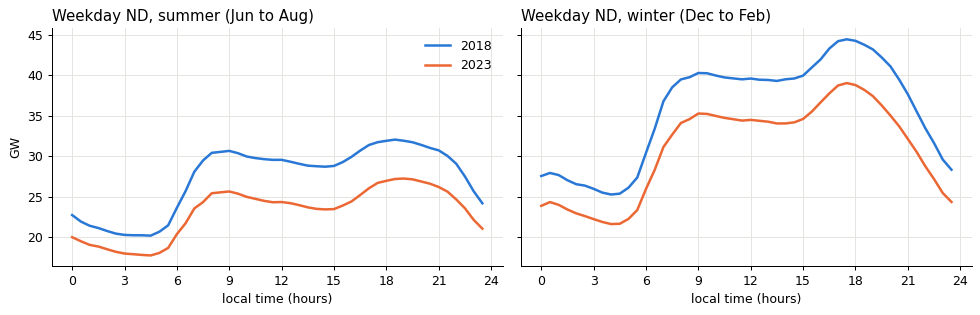

summer weekday ND (MW) at 05:00, 13:00 and 18:00
local_hour     5.0      13.0     18.0
year                                 
2018        20674.0  29053.0  31885.0
2019        19972.0  28345.0  30941.0
2020        18470.0  26234.0  29050.0
2021        19764.0  27308.0  30285.0
2022        19059.0  25168.0  28227.0
2023        18058.0  23954.0  26948.0


In [5]:
weekday_rows = demand[demand["weekday"] < 5]
seasons = {"summer (Jun to Aug)": [6, 7, 8], "winter (Dec to Feb)": [12, 1, 2]}

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, (title, months) in zip(axes, seasons.items()):
    for year, color in [(2018, BLUE), (2023, ORANGE)]:
        rows = weekday_rows[(weekday_rows["year"] == year) & weekday_rows["month"].isin(months)]
        profile = rows.groupby("local_hour")["ND"].mean() / 1000
        ax.plot(profile.index, profile.values, color=color, label=str(year))
    ax.set_title(f"Weekday ND, {title}", loc="left")
    ax.set_xticks(range(0, 25, 3))
    ax.set_xlabel("local time (hours)")
axes[0].set_ylabel("GW")
axes[0].legend(frameon=False)
fig.tight_layout()
plt.show()

summer = weekday_rows[weekday_rows["month"].isin([6, 7, 8])]
table = summer.pivot_table(index="year", columns="local_hour", values="ND", aggfunc="mean")
print("summer weekday ND (MW) at 05:00, 13:00 and 18:00")
print(table[[5.0, 13.0, 18.0]].round(0).to_string())


**Found:**

- **Summer weekday:** between 2018 and 2023, demand at 13:00 fell by 5.1 GW (29.1 to 24.0 GW,
  18%), against 2.6 GW at 05:00 (13%). By 2023 there is a clear dip at midday, below both the
  morning and the evening. This is the duck curve: embedded solar removes demand from the
  middle of the day.
- **Winter weekday:** the shape barely changed, but the whole curve dropped by about 4 to 5 GW.
  The evening peak around 17:30 is still the highest point of the year.
- So the daily shape itself drifts, and it drifts most in summer at midday, where notebook 02
  found NESO's largest errors.

**Decision:** the model needs time of day combined with solar information, not a fixed daily
profile. A tree model with time of day and solar features can learn that combination.

**Further reading:** [Duck curve](https://en.wikipedia.org/wiki/Duck_curve)
